## 使用Unet在Mnist上进行简单的条件去噪(Conditional Denoising)

In [1]:
from torchvision import datasets, transforms
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root="./data/", transform=transform, train=True, download=True)

In [2]:
image, label = train_data[0]
channel, size, _ = image.shape
print(image.shape)

torch.Size([1, 28, 28])


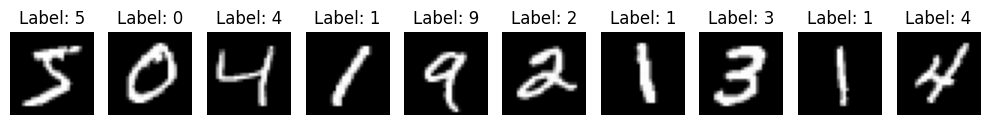

In [3]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

### 构建模型

The conditioning roughly follows the method described in [Classifier-Free Diffusion Guidance](https://arxiv.org/abs/2207.12598) (also used in [ImageGen](https://arxiv.org/abs/2205.11487)). The model infuses timestep embeddings $t_e$ and context embeddings $c_e$ with the U-Net activations at a certain layer $a_L$, via,

$$a_{L+1} = c_e  a_L + t_e.$$

(Though in our experimentation, we found variants of this also work, e.g. concatenating embeddings together.)

At training time, $c_e$ is randomly set to zero with probability $0.1$, so the model learns to do unconditional generation (say $\psi(z_t)$ for noise $z_t$ at timestep $t$) and also conditional generation (say $\psi(z_t, c)$ for context $c$). This is important as at generation time, we choose a weight, $w \geq 0$, to guide the model to generate examples with the following equation,

$$\hat{\epsilon}_{t} = (1+w)\psi(z_t, c) - w \psi(z_t).$$


Increasing $w$ produces images that are more typical but less diverse.

<center>
    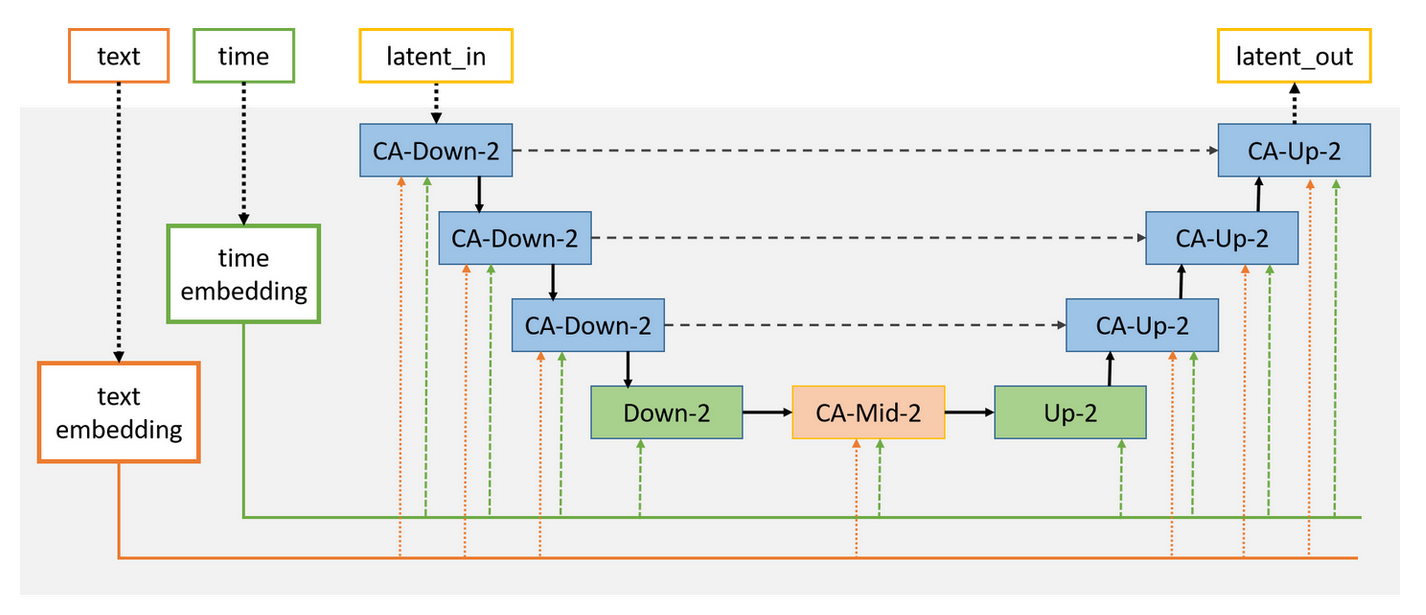
<center/>

In [33]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ResidualConvBlock(nn.Module):
    '''
    standard ResNet style convolutional block
    '''
    def __init__(self, in_channels: int, out_channels: int, is_res: bool = False) -> None:
        super().__init__()

        self.same_channels = in_channels==out_channels
        self.is_res = is_res
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1),
            nn.BatchNorm2d(out_channels),
            nn.GELU(),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, 3, 1, 1),
            nn.BatchNorm2d(out_channels),
            nn.GELU(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.is_res:
            x1 = self.conv1(x)
            x2 = self.conv2(x1)
            # this adds on correct residual in case channels have increased
            if self.same_channels:
                out = x + x2
            else:
                out = x1 + x2 
            return out / 1.414
        else:
            x1 = self.conv1(x)
            x2 = self.conv2(x1)
            return x2


class UnetDown(nn.Module):
    '''
    process and downscale the image feature maps
    '''
    def __init__(self, x_ch, out_ch, t_dim, c_dim):
        super().__init__()
        # x_ch == x_down_ch == in_ch (of model) == t_emb_dim == c_emb_dim
        self.model = nn.Sequential(
            ResidualConvBlock(x_ch, out_ch),
            nn.MaxPool2d(2)
        )
        self.time_proj = nn.Linear(t_dim, x_ch, bias=False)
        self.class_proj = nn.Linear(c_dim, x_ch, bias=False)
        
    def forward(self, x, t_emb, c_emb):
        x_ch = x.shape[1]
        t_emb = self.time_proj(t_emb).reshape(-1, x_ch, 1, 1)
        c_emb = self.class_proj(c_emb).reshape(-1, x_ch, 1, 1)
        x = c_emb * x + t_emb # 简单的融合方式，以后可以换成attention
        x = self.model(x)  
        return x


class UnetUp(nn.Module):
    '''
    process and upscale the image feature maps
    '''
    def __init__(self, x_ch, x_down_ch, out_ch, t_dim, c_dim):
        super().__init__()
        # x_ch + x_down_ch == in_ch (of model)
        # x_ch == t_emb_dim == c_emb_dim
        self.model = nn.Sequential(
            nn.ConvTranspose2d(x_ch + x_down_ch, out_ch, 2, 2),
            ResidualConvBlock(out_ch, out_ch),
            ResidualConvBlock(out_ch, out_ch),  
        )
        self.time_proj = nn.Linear(t_dim, x_ch, bias=False)
        self.class_proj = nn.Linear(c_dim, x_ch, bias=False)

    def forward(self, x, x_down, t_emb, c_emb):
        x_ch = x.shape[1]
        t_emb = self.time_proj(t_emb).reshape(-1, x_ch, 1, 1)
        c_emb = self.class_proj(c_emb).reshape(-1, x_ch, 1, 1)
        x = c_emb * x + t_emb # 简单的融合方式，以后可以换成attention
        x = torch.cat((x, x_down), 1)
        x = self.model(x)  
        return x

class TimeEmbedding(nn.Module):
    def __init__(self, n_steps, emb_dim):
        super().__init__()
        
        self.register_buffer('n_steps', torch.tensor([n_steps]))
        self.model = nn.Sequential(
            nn.Linear(1, emb_dim),
            nn.GELU(),    
        )

    def forward(self, t):
        t = t / self.n_steps # 注意这一步是tensor除法
        return self.model(t.reshape(-1, 1))

class ClassEmbedding(nn.Module):
    def __init__(self, n_classes, emb_dim):
        super().__init__()
        self.n_classes = n_classes
        self.model = nn.Sequential(
            nn.Linear(n_classes, emb_dim),
            nn.GELU(), 
        )

    def forward(self, c):
        c = F.one_hot(c, num_classes=self.n_classes).float()
        return self.model(c)

        
class ConditionalUnet(nn.Module):
    def __init__(self, in_channels=1, n_feat=128, n_steps=400, n_class=10, drop_prob=0.1):
        super().__init__()

        self.in_channels = in_channels
        self.n_feat = n_feat
        self.n_class = n_class
        self.drop_prob = drop_prob

        # embedding 维度
        self.t_dim = n_feat # // 2
        self.c_dim = n_feat # // 2

        
        self.conv_in = ResidualConvBlock(in_channels, n_feat, is_res=True)
        self.down1 = UnetDown(
            x_ch=n_feat,
            out_ch=n_feat,
            t_dim=self.t_dim,
            c_dim=self.c_dim,
        )
        self.down2 = UnetDown(
            x_ch=n_feat,
            out_ch=2 * n_feat,
            t_dim=self.t_dim,
            c_dim=self.c_dim,
        )

        self.middle = nn.Sequential(
            nn.AvgPool2d(7),
            nn.GELU(),
            # nn.ConvTranspose2d(6 * n_feat, 2 * n_feat, 7, 7), # when concat temb and cemb end up w 6*n_feat
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, 7, 7), # otherwise just have 2*n_feat
            nn.GroupNorm(8, 2 * n_feat),
            nn.ReLU(),
        )

        self.up1 = UnetUp(
            x_ch =2*n_feat,
            x_down_ch=2*n_feat,
            out_ch=n_feat,
            t_dim=self.t_dim,
            c_dim=self.c_dim,
        )
        self.up2 = UnetUp(
            x_ch =n_feat,
            x_down_ch=n_feat,
            out_ch=n_feat,
            t_dim=self.t_dim,
            c_dim=self.c_dim,
        )
        
        self.conv_out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, 3, 1, 1),
            nn.GroupNorm(8, n_feat),
            nn.ReLU(),
            nn.Conv2d(n_feat, self.in_channels, 3, 1, 1),
        )

        self.time_emb = TimeEmbedding(n_steps, self.t_dim)
        self.class_emb = ClassEmbedding(n_class, self.c_dim)
    
    def forward(self, x, t, c): #, context_mask):
        # x is (noisy) image, c is context label, t is timestep, 
        # context_mask says which samples to block the context on
        # x:[n, 1, 28, 28]
        # t: [n,] | [n, 1] | [n, 1, 1, ...]
        # c: [n,] | [n, 1] | [n, 1, 1, ...]
        # Note: as you can see above, we are compatible with various possible tensor dimensions of x, t

        x = self.conv_in(x)
        t_emb = self.time_emb(t)

        if (c is None) or (self.training and self.drop_prob and torch.rand(1).item() < self.drop_prob):
            # no condition or employ train dropout
            n = x.shape[0]
            c_emb = torch.zeros(n, self.c_dim, device=x.device, dtype=torch.float) # 全0的embedding，意味着无条件生成
        else:
            c_emb = self.class_emb(c)
            
        
        down1 = self.down1(x, t_emb, c_emb)
        down2 = self.down2(down1, t_emb, c_emb)

        up1 = self.middle(down2)
        
        # up2 = self.up1(up1, down2) # if want to avoid add and multiply embeddings
        up2 = self.up1(up1, down2, t_emb, c_emb)  # add and multiply embeddings
        up3 = self.up2(up2, down1, t_emb, c_emb)
        out = self.conv_out(torch.cat((up3, x), 1))
        return out

In [34]:
# unit test
def unit_test():
    net = ConditionalUnet(1, 128, 400, 10)
    
    # 20 samples of  random imgs with the shape of mnist
    x = torch.randn(20, 1, 28, 28) 
    t = torch.randint(0, 50, size=(20,))
    c = torch.randint(0, 10, size=(20,))

    test_out = net(x, t, c) # 没报错就行

    print('pass')

unit_test()

pass


In [35]:
import torch.nn.functional as F

class ConditionalDDPM():
    """
    条件控制的DDPM算法:
    和DDPM算法相比只是在model推理中增加了条件项c
    同时注意产生时间步t的时候和输入形状对齐
    """
    def __init__(self, betas, device):
        super().__init__()
        self.device = device
        self.n_steps = len(betas)

        self.model = ConditionalUnet(in_channels=1, n_feat=128, n_steps=self.n_steps, n_class=10, drop_prob=0.0).to(device)

        # 预先计算一些数据方便计算
        self.betas = betas.to(device)
        self.betas_sqrt = self.betas.sqrt()
        
        self.alphas = 1 - self.betas
        self.alphas_sqrt = self.alphas.sqrt()
        self.alphas_bar = self.alphas.cumprod(dim=0)
        self.alphas_bar_sqrt = self.alphas_bar.sqrt()
        self.alphas_minus_1_bar = F.pad(self.alphas_bar[1:], (1, 0), value=1.)
        self.one_minus_alphas_bar_sqrt = torch.sqrt(1 - self.alphas_bar)

    def q_x(self, x_0, t):
        """
        前向传播函数，添加了返回的e_t用于计算loss
        作用：前向过程, 可以基于x[0]和条件c, 得到任意时刻t的x[t]
        输入：x_0:初始干净图像；t：采样步
        输出：x_t:第t步时的x_0已成为的样子
             e_t: 添加的噪声（用于计算loss）
        """
        t = t.reshape(-1, 1, 1, 1)
        noise = torch.randn_like(x_0)  # noise为从正态分布中采样的随机噪声
        
        alphas_t = self.alphas_bar_sqrt[t]  # 根号下αt^
        alphas_1_m_t = self.one_minus_alphas_bar_sqrt[t]  # 根号下(1-αt^)
        
        return alphas_t * x_0 + alphas_1_m_t * noise, noise

    def diffusion_loss(self, x_0, c):
        """
        this method is used in training, so samples t and noise randomly
        """
        
        # 对一个batchsize样本生成随机的时刻t，尤其注意维度对齐
        batch_size = x_0.shape[0]
        t = torch.randint(0, self.n_steps, size=(batch_size, 1, 1, 1), device=self.device)
        
        # 构造模型的输入
        x_t, e_t = self.q_x(x_0, t)  # 前向过程：根号下αt^ * x0 + 根号下(1-αt^) * eps

        # # dropout context with some probability???
        # context_mask = torch.bernoulli(torch.zeros_like(c)+self.drop_prob).to(self.device)
        
        # 建模噪声
        output = self.model(x_t, t, c)  # 模型预测的是噪声, 噪声维度与x0一样大, [10000,2]
        
        # 与真实噪声一起计算误差，求平均值
        return F.mse_loss(output, e_t)

    
    @torch.no_grad()
    def p_sample(self, noise, c, n_steps, guide_w=.0, return_trajectory=True):
        """
        作用：从x[T]恢复x[T-1]、x[T-2]、...x[0]
        输入：
            shape:数据大小,用于生成随机噪声
        输出：
            x_seq：一个序列的x, 即 x[T]、x[T-1]、x[T-2]、...x[0]
        """
        # we follow the guidance sampling scheme described in 'Classifier-Free Diffusion Guidance'
        # to make the fwd passes efficient, we concat two versions of the dataset,
        # one with context_mask=0 and the other context_mask=1
        # we then mix the outputs with the guidance scale, w
        # where w>0 means more guidance
        
        assert n_steps <= self.n_steps
        cur_x = noise
        x_seq = [cur_x]
        for i in reversed(range(n_steps)):
            cur_x = self._p_sample_step(cur_x, i, c, guide_w)
            if return_trajectory:
                x_seq.append(cur_x)
            else:
                x_seq = [cur_x]
        return x_seq

    @torch.no_grad()
    def _p_sample_step(self, x_t, t, c, guide_w):
        """
        作用：采样一步
        输入：x_t, t
        输出：
            模型从x_t预测的x_{t-1}
        """
        t = torch.tensor([t], device=self.device)
        
        coeff = self.betas[t] / self.one_minus_alphas_bar_sqrt[t]  # 模型输出的系数：βt/根号下(1-αt^) = 1-αt/根号下(1-αt^)

        ##Note: 条件生成模型里面加的
        # eps_cond = self.model(x_t, t, c)  # 有条件生成
        # eps_uncond = self.model(x_t, t, c=None)  # 无条件生成
        # eps_theta = (1 + guide_w) * eps_cond - guide_w * eps_uncond # 真正的输出是有条件和无条件的加成
        eps_theta = self.model(x_t, t, c)
            
        # 见algorithm-2
        mean = (1 / self.alphas_sqrt[t]) * (x_t - (coeff * eps_theta))  
        
        z = torch.randn_like(x_t)  # 对应公式中的 z
        
        sigma_t = self.betas[t].sqrt()  # 对应公式中的 σt 
        
        return mean + sigma_t * z 

    def save(self, file):
        state = {
            'betas': self.betas,
            'model': self.model.state_dict(),
        }
        torch.save(state, file)

    @classmethod
    def load_from_checkpoint(cls, file, device):
        state = torch.load(file, map_location=device, weights_only=True)
        ddpm = cls(betas=state['betas'], device=device)
        ddpm.model.load_state_dict(state['model'], strict=True)
        return ddpm

In [36]:
def linear_beta_scheduler(beta1, beta2, n_step):
    assert 0 < beta1 < beta2 < 1
    return torch.linspace(beta1, beta2, n_step)
    
betas = linear_beta_scheduler(1e-4, 0.02, n_step=400)

In [46]:
from tqdm import tqdm
from torch.utils.data import DataLoader

print('Training model...')
batch_size = 256
num_epoch = 21
lr=1e-4
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

ddpm = ConditionalDDPM(betas, device)
optimizer = torch.optim.Adam(ddpm.model.parameters(), lr=lr)

train_dataloader = DataLoader(train_data, batch_size=batch_size, shuffle=True)

x_seq_list = []

with tqdm(total=num_epoch*len(train_dataloader)) as pbar:
    for t in range(num_epoch):
        pbar.set_description(f'Epoch {t+1}')
        loss_ema = None
        ddpm.model.train()
        optimizer.param_groups[0]['lr'] = lr*(1-t/num_epoch) # linear decay
        for imgs, labels in train_dataloader:
            imgs, labels = imgs.to(device), labels.to(device)
            # 损失计算
            loss = ddpm.diffusion_loss(imgs, labels)
            optimizer.zero_grad()  # 梯度清零
            loss.backward()  # 损失回传
            if loss_ema is None:
                loss_ema = loss.item()
            else:
                loss_ema = 0.95 * loss_ema + 0.05 * loss.item()
            optimizer.step()
            pbar.update(1)
            pbar.set_postfix(loss=f'{loss_ema:.4f}')
 
        if(t % 5 == 0):
            ddpm.model.eval()
            noise = torch.randn((10, 1, 28, 28), device=device)  # 输入随机噪声，用1/10样本采样即可，节省空间
            c = torch.arange(10, device=device) # 0-9的标签作为条件
            x_seq = ddpm.p_sample(noise, c, n_steps=400, return_trajectory=False)
            x_seq_list.append(x_seq[0])
        

Training model...


Epoch 21: 100%|████████████████| 4935/4935 [30:47<00:00,  2.67it/s, loss=0.0382]


In [47]:
ddpm.save('./checkpoints/test_21epoch_no_guide_w_linear_lr_decay_up_mixin.pt')

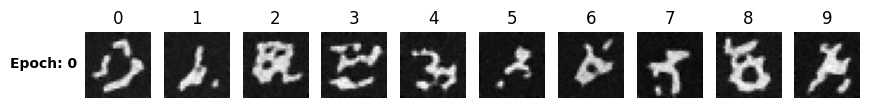

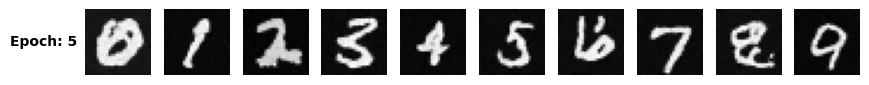

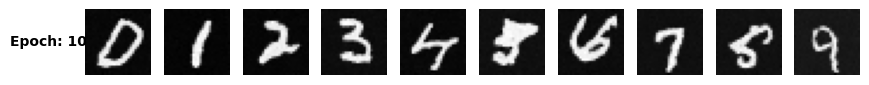

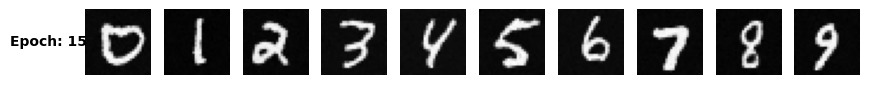

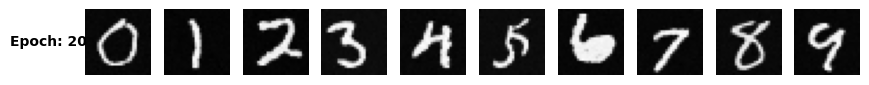

In [48]:
# def unit_test():
#     noise = torch.randn((10, 1, 28, 28), device=device)  # 输入随机噪声，用1/10样本采样即可，节省空间
#     c = torch.arange(10, device=device) # 0-9的标签作为条件
#     x_seq = ddpm.p_sample(noise, c, n_steps=400, return_tr)
#     return  [x_seq[0].cpu()] * 5

# x_seq_list = unit_test()

# 遍历前10张图片
plt.rc('text',color='black')
for k, x_seq in enumerate(x_seq_list):
    x_seq = x_seq.cpu()
    fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
    fig.text(0.05, 0.5, f'Epoch: {k*5}', ha='left', va='center', fontweight='black')
    for i in range(10):
        ax = axes[i]  # 获取当前子图
        ax.imshow(x_seq[i][0], cmap='gray')  # 显示灰度图
        ax.axis('off')  # 关闭坐标轴
        if k == 0:
            ax.set_title(f'{i}')  # 显示标签

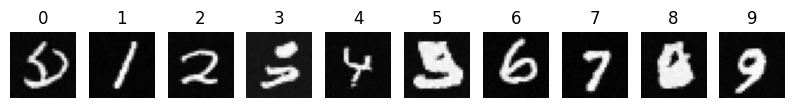

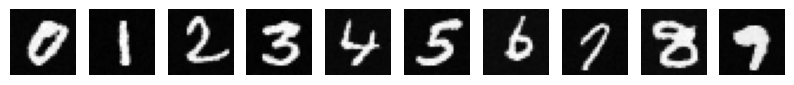

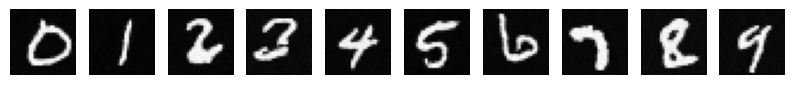

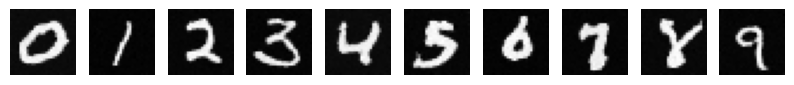

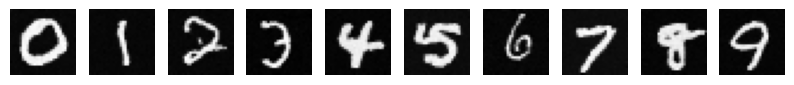

In [49]:
def unit_test():
    noise = torch.randn((10, 1, 28, 28), device=device)  # 输入随机噪声，用1/10样本采样即可，节省空间
    c = torch.arange(10, device=device) # 0-9的标签作为条件
    x_seq = ddpm.p_sample(noise, c, n_steps=400, return_trajectory=False)
    return  x_seq[0].cpu()

x_emp_list = [unit_test() for _ in range(5)]

# 遍历前10张图片
plt.rc('text',color='black')
for k, x_seq in enumerate(x_emp_list):
    x_seq = x_seq.cpu()
    fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
    # fig.text(0.05, 0.5, f'Epoch: {k*5}', ha='left', va='center', fontweight='black')
    for i in range(10):
        ax = axes[i]  # 获取当前子图
        ax.imshow(x_seq[i][0], cmap='gray')  # 显示灰度图
        ax.axis('off')  # 关闭坐标轴
        if k == 0:
            ax.set_title(f'{i}')  # 显示标签

## 无标签随机生成

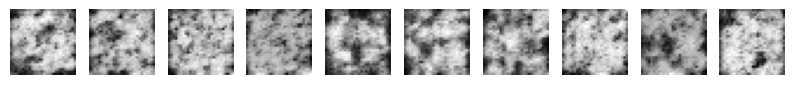

In [50]:
# noise = torch.randn((1, 1, 28, 28), device=device)  # 输入随机噪声，用1/10样本采样即可，节省空间
# x_seq = ddpm.p_sample(noise, c=None, n_steps=400, return_trajectory=False)
# image = x_seq[0].cpu()

# # plot
# plt.figure(figsize=(2, 2))  # 设置图形大小为4x4英寸
# plt.imshow(image[0][0], cmap='gray')  # `image[0]` 是单通道（灰度）图像
# plt.axis('off')  # 关闭坐标轴
# plt.show()
def unit_test():
    noise = torch.randn((10, 1, 28, 28), device=device)  # 输入随机噪声，用1/10样本采样即可，节省空间
    x_seq = ddpm.p_sample(noise, c=None, n_steps=400, return_trajectory=False)
    return  x_seq[0].cpu()

x_emp_list = [unit_test()]

# 遍历前10张图片
plt.rc('text',color='black')
for k, x_seq in enumerate(x_emp_list):
    x_seq = x_seq.cpu()
    fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
    # fig.text(0.05, 0.5, f'Epoch: {k*5}', ha='left', va='center', fontweight='black')
    for i in range(10):
        ax = axes[i]  # 获取当前子图
        ax.imshow(x_seq[i][0], cmap='gray')  # 显示灰度图
        ax.axis('off')  # 关闭坐标轴

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ddpm = ConditionalDDPM.load_from_checkpoint('0220-test.pt', device)